# Imports & Paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import re
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

DATA_DIR = Path("../data")  # place the CSVs listed in data/README.md here

expr_path = DATA_DIR / "SC_expression.csv"
cond_path = DATA_DIR / "conditions_annotation.csv"
bp_path   = DATA_DIR / "labels_BP.csv"
cc_path   = DATA_DIR / "labels_CC.csv"
mf_path   = DATA_DIR / "labels_MF.csv"

# Load expression matrix

In [2]:
expr_raw = pd.read_csv(expr_path, index_col=0)

print("Raw shape (genes × samples):", expr_raw.shape)
print("First 5 gene names:", expr_raw.index[:5].tolist())
print("First 5 sample IDs:", expr_raw.columns[:5].tolist())

expr_df = expr_raw.T
expr_df.index.name = "sample_id"

print("\nTransposed shape (samples × genes):", expr_df.shape)
print("Sample index (first 5):", expr_df.index[:5].tolist())
print("Gene columns (first 5):", expr_df.columns[:5].tolist())

Raw shape (genes × samples): (6071, 92)
First 5 gene names: ['YAL008W', 'YBR255W', 'YGR164W', 'YGR131W', 'YNL003C']
First 5 sample IDs: ['IFFABF', 'SAASCC', 'IFFAFF', 'IFFAFA', 'INICIA']

Transposed shape (samples × genes): (92, 6071)
Sample index (first 5): ['IFFABF', 'SAASCC', 'IFFAFF', 'IFFAFA', 'INICIA']
Gene columns (first 5): ['YAL008W', 'YBR255W', 'YGR164W', 'YGR131W', 'YNL003C']


# Load conditions & resolve duplicate IDs explicitly

In [3]:
cond_df = pd.read_csv(cond_path)

print("Shape:", cond_df.shape)
print("Columns:", cond_df.columns.tolist())

# --- Label normalization: strip whitespace, unify known aliases ---
LABEL_ALIASES = {
    "wild type": "wildtype",
    "hybrid  cerevisiae x  paradoxus ": "hybrid  cerevisiae x  paradoxus",
}
cond_df["primary"] = (
    cond_df["primary"]
    .str.strip()
    .replace(LABEL_ALIASES)
)

print("\nUnique primary conditions after normalization:")
print(cond_df["primary"].value_counts())

# --- Explicit duplicate ID resolution ---
dupes = cond_df[cond_df["ID"].duplicated(keep=False)].copy()
print(f"\nDuplicate IDs ({len(dupes)} rows):")
print(dupes[["ID", "primary", "secondary"]].sort_values("ID").to_string())

# For each duplicated ID:
#   - If all rows share the same label → safe to keep one (they are technical replicates)
#   - If rows have conflicting labels → ambiguous; drop all rows for that ID
same_label_dupes = set()
conflict_dupes   = set()

for id_val, group in dupes.groupby("ID"):
    if group["primary"].nunique() == 1:
        same_label_dupes.add(id_val)
    else:
        conflict_dupes.add(id_val)

print(f"\nSame-label duplicates (keep first): {sorted(same_label_dupes)}")
print(f"Conflicting-label duplicates (DROP): {sorted(conflict_dupes)}")

# Drop conflicting-label rows entirely
cond_df = cond_df[~cond_df["ID"].isin(conflict_dupes)]
# For same-label dupes, keep the first occurrence
cond_df = cond_df.drop_duplicates(subset="ID", keep="first")

cond_df = cond_df.set_index("ID")
print(f"\nConditions after deduplication: {len(cond_df)} rows")

Shape: (92, 4)
Columns: ['ID', 'primary', 'secondary', 'additional_information']

Unique primary conditions after normalization:
primary
wildtype                           8
37 deg                             8
hybrid  cerevisiae x  paradoxus    4
Strain6                            4
30 deg                             4
15 deg                             4
YB210                              3
YB211                              3
YB213                              3
YB212                              3
pbs2                               3
swr1                               2
MATa MAL2-8c SUC2                  2
rrp6                               2
anMX4                              2
Strain7                            2
Strain5                            2
tet-control strain                 2
tet-INO80                          2
tet-STH1                           2
itc1                               2
MATa ura3-52 his3-1 leu2-3         2
fy3                                2
DDY3630     

# Merge expression matrix with condition labels

In [4]:
label_col = "primary"

merged = expr_df.join(cond_df[[label_col]], how="inner")

print("Merged shape:", merged.shape)
print(f"Samples matched: {len(merged)} / {len(expr_df)} total")
print(f"\nLabel ('{label_col}') value counts:")
print(merged[label_col].value_counts())

gene_cols = expr_df.columns.tolist()
X = merged[gene_cols]
y = merged[label_col]

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Unique classes: {sorted(y.unique().tolist())}")

Merged shape: (85, 6072)
Samples matched: 85 / 92 total

Label ('primary') value counts:
primary
wildtype                           8
37 deg                             8
30 deg                             4
hybrid  cerevisiae x  paradoxus    4
YB212                              3
pbs2                               3
YB211                              3
Strain6                            3
YB213                              3
15 deg                             3
Strain7                            2
YB210                              2
Strain5                            2
anMX4                              2
tet-control strain                 2
itc1                               2
MATa ura3-52 his3-1 leu2-3         2
tet-INO80                          2
fy3                                2
rrp6                               2
MATa MAL2-8c SUC2                  2
tet-STH1                           2
swr1                               2
E1B1                               1
DDY3630        

# Filter low-sample classes & reset index

In [5]:
vc = y.value_counts()
valid_classes   = vc[vc >= 2].index
dropped_classes = vc[vc < 2].index.tolist()

print("Class counts before filtering:")
print(vc.to_string())

if dropped_classes:
    print(f"\nDropping {len(dropped_classes)} class(es) with < 2 samples: {dropped_classes}")

mask = y.isin(valid_classes)
X_filtered = X.loc[mask].reset_index(drop=True)
y_filtered = y.loc[mask].reset_index(drop=True)

print(f"\nAfter filtering:")
print(f"X shape: {X_filtered.shape}")
print(f"y shape: {y_filtered.shape}")
print(f"Classes remaining: {y_filtered.nunique()}")
print(f"\nIndex aligned: {X_filtered.index.equals(y_filtered.index)}")

Class counts before filtering:
primary
wildtype                           8
37 deg                             8
30 deg                             4
hybrid  cerevisiae x  paradoxus    4
YB212                              3
pbs2                               3
YB211                              3
Strain6                            3
YB213                              3
15 deg                             3
Strain7                            2
YB210                              2
Strain5                            2
anMX4                              2
tet-control strain                 2
itc1                               2
MATa ura3-52 his3-1 leu2-3         2
tet-INO80                          2
fy3                                2
rrp6                               2
MATa MAL2-8c SUC2                  2
tet-STH1                           2
swr1                               2
E1B1                               1
DDY3630                            1
G2A1                               1

# Label normalization audit 

In [6]:
print("Final unique classes:")
for cls, cnt in y_filtered.value_counts().items():
    print(f"  {cnt:3d}  '{cls}'")

# Sanity check: no two class names should differ only by whitespace
classes = y_filtered.unique()
stripped = [c.strip() for c in classes]
if len(set(stripped)) < len(stripped):
    print("\nWARNING: whitespace duplicates still detected — review LABEL_ALIASES in Cell 3")
else:
    print("\nOK: no whitespace/alias duplicates detected")

Final unique classes:
    8  'wildtype'
    8  '37 deg'
    4  '30 deg'
    4  'hybrid  cerevisiae x  paradoxus'
    3  'YB211'
    3  'Strain6'
    3  'pbs2'
    3  'YB213'
    3  '15 deg'
    3  'YB212'
    2  'YB210'
    2  'itc1'
    2  'tet-control strain'
    2  'Strain7'
    2  'rrp6'
    2  'MATa ura3-52 his3-1 leu2-3'
    2  'tet-INO80'
    2  'swr1'
    2  'fy3'
    2  'tet-STH1'
    2  'MATa MAL2-8c SUC2'
    2  'anMX4'
    2  'Strain5'

OK: no whitespace/alias duplicates detected



# Label encoding


In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y_filtered)
print(f"Classes ({len(le.classes_)}):\n{le.classes_}")
print(f"Encoded y unique: {np.unique(y_encoded)}")

Classes (23):
['15 deg' '30 deg' '37 deg' 'MATa MAL2-8c SUC2'
 'MATa ura3-52 his3-1 leu2-3' 'Strain5' 'Strain6' 'Strain7' 'YB210'
 'YB211' 'YB212' 'YB213' 'anMX4' 'fy3' 'hybrid  cerevisiae x  paradoxus'
 'itc1' 'pbs2' 'rrp6' 'swr1' 'tet-INO80' 'tet-STH1' 'tet-control strain'
 'wildtype']
Encoded y unique: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]


# Exploratory PCA scree plot

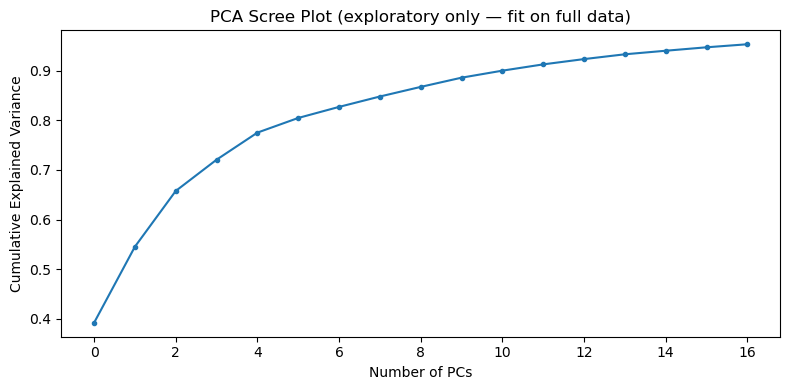

In [8]:
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

_selector = VarianceThreshold(threshold=1.0)
_X_var    = _selector.fit_transform(X_filtered)
_scaler   = StandardScaler()
_X_scaled = _scaler.fit_transform(_X_var)

_pca = PCA(n_components=0.95, random_state=42)
_pca.fit(_X_scaled)

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(_pca.explained_variance_ratio_), marker='o', markersize=3)
plt.xlabel("Number of PCs")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Scree Plot (exploratory only — fit on full data)")
plt.tight_layout()
plt.savefig("pca_scree.png", dpi=150)
plt.show()

del _selector, _X_var, _scaler, _X_scaled, _pca

# VAE definition (architecture + training helpers)

In [9]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

latent_dim = 16  # tunable: try 8, 16, 32

class VAE(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
        )
        self.mu_layer     = nn.Linear(64, latent_dim)
        self.logvar_layer = nn.Linear(64, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, input_dim),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.mu_layer(h), self.logvar_layer(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar


def vae_loss(recon_x, x, mu, logvar, beta=1.0):
    recon = nn.functional.mse_loss(recon_x, x, reduction="sum")
    kld   = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + beta * kld


def train_vae(X_train_np, input_dim, latent_dim=16, n_epochs=200,
              batch_size=16, lr=1e-3, beta=1.0):
    """Train a fresh VAE on X_train_np and return the trained model."""
    X_t     = torch.tensor(X_train_np, dtype=torch.float32)
    loader  = DataLoader(TensorDataset(X_t), batch_size=batch_size, shuffle=True)
    model   = VAE(input_dim, latent_dim)
    optim   = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for _ in range(n_epochs):
        for (batch,) in loader:
            optim.zero_grad()
            recon, mu, logvar = model(batch)
            loss = vae_loss(recon, batch, mu, logvar, beta=beta)
            loss.backward()
            optim.step()
    return model


def encode_vae(model, X_np):
    """Extract mean latent vectors (no gradient) for X_np."""
    model.eval()
    with torch.no_grad():
        mu, _ = model.encode(torch.tensor(X_np, dtype=torch.float32))
    return mu.numpy()



## Exploratory VAE visualization

Training exploratory VAE for visualization (full data — not used in CV)...


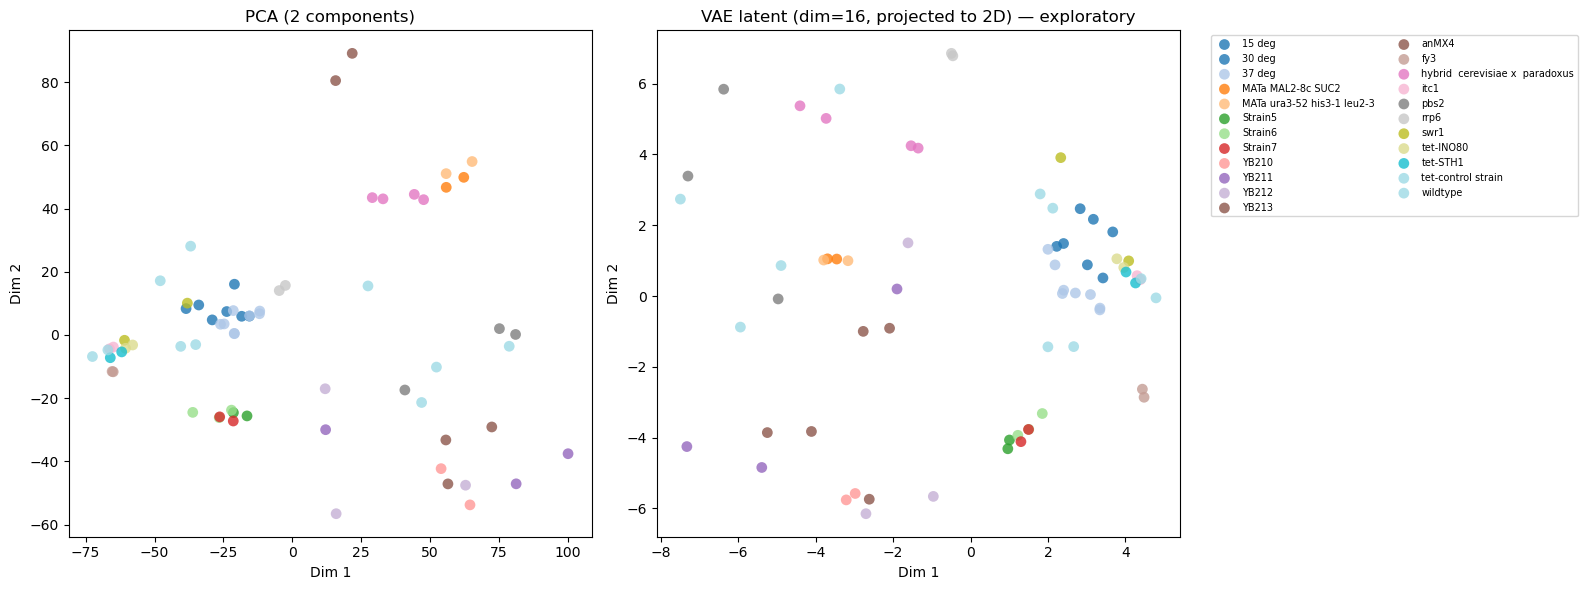

In [10]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA as PCA_plot

# Preprocessing for visualization (fit on full data — exploratory)
_sel    = VarianceThreshold(threshold=1.0)
_Xv     = _sel.fit_transform(X_filtered)
_sc     = StandardScaler()
_Xs     = _sc.fit_transform(_Xv)

print("Training exploratory VAE for visualization (full data — not used in CV)...")
_vae_vis = train_vae(_Xs, input_dim=_Xs.shape[1], latent_dim=latent_dim, n_epochs=200)
X_vae_vis = encode_vae(_vae_vis, _Xs)

# PCA 2D projection for comparison
X_pca2  = PCA_plot(n_components=2, random_state=42).fit_transform(_Xs)
X_vae2  = PCA_plot(n_components=2, random_state=42).fit_transform(X_vae_vis) \
          if latent_dim > 2 else X_vae_vis

cmap = plt.colormaps["tab20"].resampled(len(le.classes_))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, X_2d, title in zip(
    axes,
    [X_pca2, X_vae2],
    ["PCA (2 components)", f"VAE latent (dim={latent_dim}, projected to 2D) — exploratory"]
):
    for i, cls in enumerate(le.classes_):
        mask = (y_encoded == i)
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                   label=cls, color=cmap(i), alpha=0.8, s=60, edgecolors='none')
    ax.set_title(title)
    ax.set_xlabel("Dim 1"); ax.set_ylabel("Dim 2")

axes[1].legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("pca_vs_vae_exploratory.png", dpi=150, bbox_inches="tight")
plt.show()

del _sel, _Xv, _sc, _Xs, _vae_vis


# Cross-validation

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

def make_pipeline(classifier):
    return Pipeline([
        ("var",   VarianceThreshold(threshold=1.0)),
        ("scale", StandardScaler()),
        ("pca",   PCA(n_components=0.95, random_state=42)),
        ("clf",   classifier),
    ])

min_class_count = y_filtered.value_counts().min()
n_splits = min(5, min_class_count)
print(f"Using n_splits={n_splits} (min class count = {min_class_count})")
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

pipelines = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=5000, solver="saga", C=0.1, random_state=42)
    ),
    "Random Forest": make_pipeline(
        RandomForestClassifier(n_estimators=200, random_state=42)
    ),
    "SVM (RBF)": make_pipeline(
        SVC(kernel="rbf", random_state=42)
    ),
    "KNN (k=5)": make_pipeline(
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Gradient Boosting": make_pipeline(
        GradientBoostingClassifier(n_estimators=100, random_state=42)
    ),
}

results = {}

# --- PCA-based pipelines ---
X_arr = X_filtered.values
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_arr, y_encoded, cv=cv,
                             scoring="accuracy", n_jobs=-1)
    results[name] = scores
    print(f"{name:30s}  acc={scores.mean():.4f} ± {scores.std():.4f}")

# --- Leak-free VAE + SVM cross-validation ---
# The VAE is retrained from scratch on each fold's TRAINING data only.
# Test-fold samples are encoded using that fold's model — they are never seen during VAE training.
print("\nRunning VAE CV...")
vae_fold_scores = []

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_arr, y_encoded)):
    X_tr, X_te = X_arr[train_idx], X_arr[test_idx]
    y_tr, y_te = y_encoded[train_idx], y_encoded[test_idx]

    # Preprocessing fit on train fold only
    sel   = VarianceThreshold(threshold=1.0).fit(X_tr)
    X_tr_ = sel.transform(X_tr)
    X_te_ = sel.transform(X_te)
    sc    = StandardScaler().fit(X_tr_)
    X_tr_ = sc.transform(X_tr_)
    X_te_ = sc.transform(X_te_)

    # Train VAE on train fold only
    fold_vae = train_vae(X_tr_, input_dim=X_tr_.shape[1],
                         latent_dim=latent_dim, n_epochs=200)

    # Encode both splits using the fold-trained VAE
    Z_tr = encode_vae(fold_vae, X_tr_)
    Z_te = encode_vae(fold_vae, X_te_)

    # SVM on latent space
    svm_sc = StandardScaler().fit(Z_tr)
    clf    = SVC(kernel="rbf", random_state=42)
    clf.fit(svm_sc.transform(Z_tr), y_tr)
    y_pred_fold = clf.predict(svm_sc.transform(Z_te))

    fold_acc = accuracy_score(y_te, y_pred_fold)
    vae_fold_scores.append(fold_acc)
    print(f"  Fold {fold_idx+1}: acc={fold_acc:.4f}")

vae_fold_scores = np.array(vae_fold_scores)
results["VAE + SVM"] = vae_fold_scores
print(f"\n{'VAE + SVM':30s}  acc={vae_fold_scores.mean():.4f} ± {vae_fold_scores.std():.4f}")

Using n_splits=2 (min class count = 2)
Logistic Regression             acc=0.5147 ± 0.0735
Random Forest                   acc=0.5000 ± 0.0588
SVM (RBF)                       acc=0.3824 ± 0.0294
KNN (k=5)                       acc=0.2647 ± 0.0588
Gradient Boosting               acc=0.3824 ± 0.0000

Running VAE CV...
  Fold 1: acc=0.4118
  Fold 2: acc=0.3824

VAE + SVM                       acc=0.3971 ± 0.0147



# Best model evaluation + confusion matrix


Best model: Logistic Regression  (CV acc=0.5147)

Classification Report:
                    precision    recall  f1-score   support

            37 deg       1.00      1.00      1.00         1
 MATa MAL2-8c SUC2       0.00      0.00      0.00         1
           Strain5       0.25      1.00      0.40         1
           Strain6       0.00      0.00      0.00         2
           Strain7       0.00      0.00      0.00         2
             YB212       0.00      0.00      0.00         1
             YB213       0.00      0.00      0.00         1
              itc1       0.00      0.00      0.00         1
              pbs2       1.00      0.50      0.67         2
              swr1       0.00      0.00      0.00         1
tet-control strain       1.00      1.00      1.00         1

         micro avg       0.50      0.29      0.36        14
         macro avg       0.30      0.32      0.28        14
      weighted avg       0.30      0.29      0.27        14



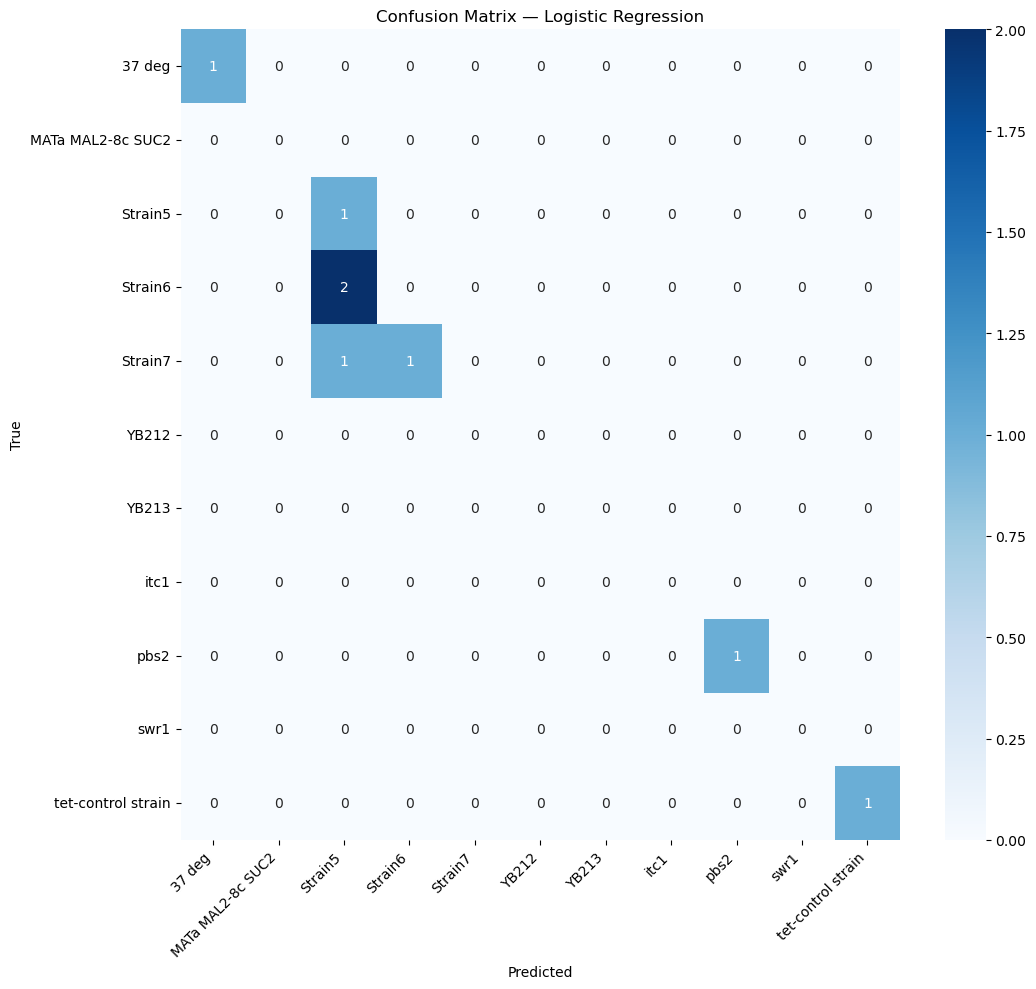

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

best_name = max(results, key=lambda k: results[k].mean())
print(f"Best model: {best_name}  (CV acc={results[best_name].mean():.4f})")

# --- Final hold-out evaluation ---
try:
    X_train, X_test, y_train, y_test = train_test_split(
        X_arr, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)
except ValueError:
    print("Warning: stratified split failed — using random split.")
    X_train, X_test, y_train, y_test = train_test_split(
        X_arr, y_encoded, test_size=0.2, random_state=42)

if best_name == "VAE + SVM (leak-free)":
    # Retrain VAE on train split only
    sel_f  = VarianceThreshold(threshold=1.0).fit(X_train)
    Xtr_   = sel_f.transform(X_train)
    Xte_   = sel_f.transform(X_test)
    sc_f   = StandardScaler().fit(Xtr_)
    Xtr_   = sc_f.transform(Xtr_)
    Xte_   = sc_f.transform(Xte_)
    best_vae = train_vae(Xtr_, input_dim=Xtr_.shape[1], latent_dim=latent_dim, n_epochs=200)
    Ztr    = encode_vae(best_vae, Xtr_)
    Zte    = encode_vae(best_vae, Xte_)
    svm_sc = StandardScaler().fit(Ztr)
    clf_final = SVC(kernel="rbf", random_state=42)
    clf_final.fit(svm_sc.transform(Ztr), y_train)
    y_pred = clf_final.predict(svm_sc.transform(Zte))
    y_test_plot = y_test
else:
    best_pipe = pipelines[best_name]
    best_pipe.fit(X_train, y_train)
    y_pred = best_pipe.predict(X_test)
    y_test_plot = y_test

present_labels = np.unique(y_test_plot)
present_names  = le.classes_[present_labels]

print("\nClassification Report:")
print(classification_report(
    y_test_plot, y_pred,
    labels=present_labels,
    target_names=present_names,
    zero_division=0
))

cm = confusion_matrix(y_test_plot, y_pred, labels=present_labels)
fig_size = max(6, len(present_labels))
plt.figure(figsize=(fig_size, fig_size - 1))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=present_names, yticklabels=present_names)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# Full results visualization — PCA, VAE, model comparison

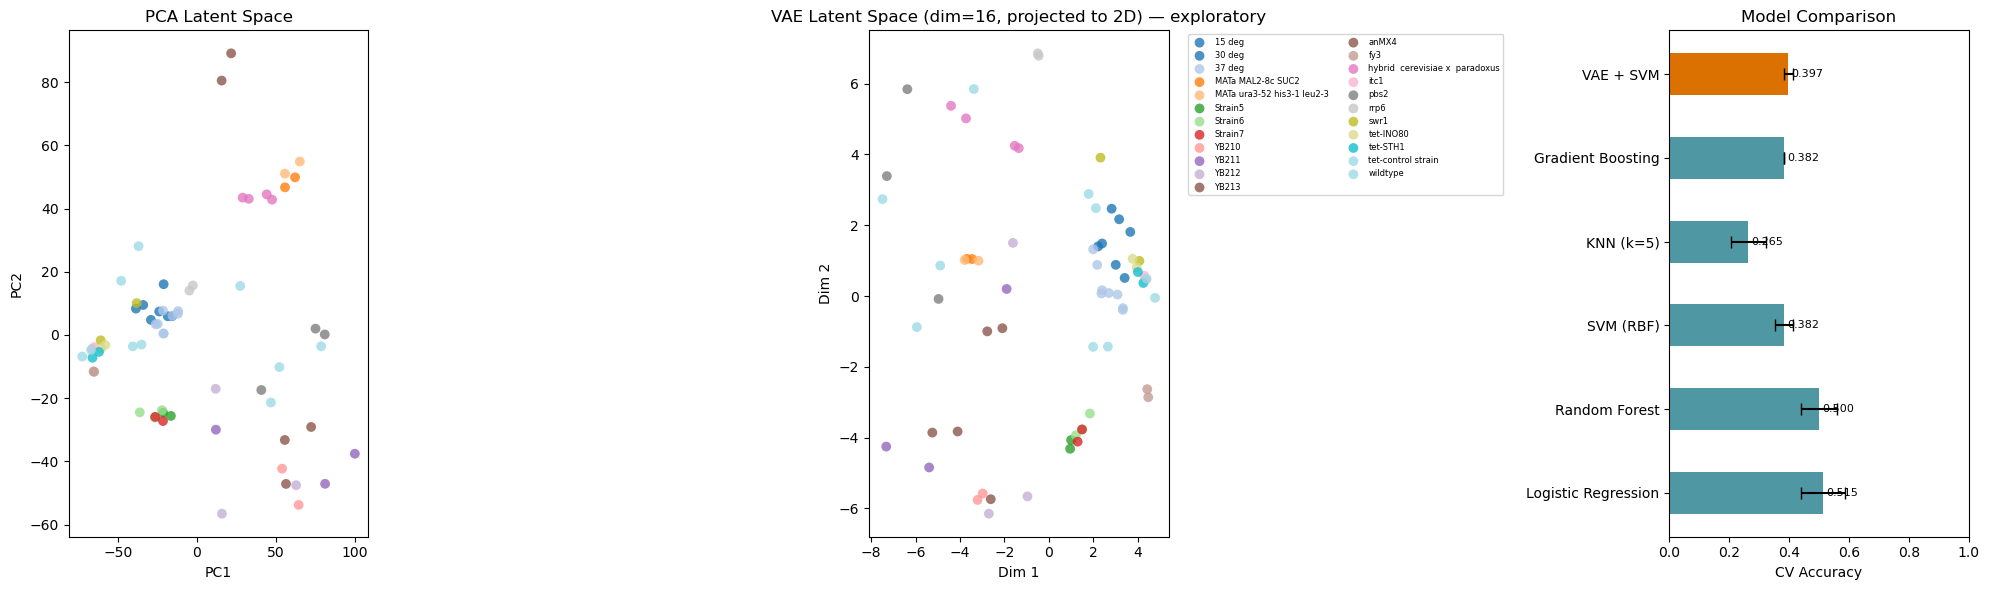

Saved full_results.png


In [13]:
from sklearn.decomposition import PCA as PCA2

cmap = plt.colormaps["tab20"].resampled(len(le.classes_))

# 2D projections (exploratory — fit on full data for plotting only)
_pipe_pca = Pipeline([
    ("var",   VarianceThreshold(threshold=1.0)),
    ("scale", StandardScaler()),
    ("pca",   PCA(n_components=2, random_state=42)),
])
X_pca_2d = _pipe_pca.fit_transform(X_arr)
X_vae_2d = PCA2(n_components=2, random_state=42).fit_transform(X_vae_vis) \
           if latent_dim > 2 else X_vae_vis

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Panel 1: PCA scatter
ax = axes[0]
for i, cls in enumerate(le.classes_):
    mask = (y_encoded == i)
    ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
               label=cls, color=cmap(i), alpha=0.8, s=50, edgecolors='none')
ax.set_title("PCA Latent Space")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

# Panel 2: VAE scatter
ax = axes[1]
for i, cls in enumerate(le.classes_):
    mask = (y_encoded == i)
    ax.scatter(X_vae_2d[mask, 0], X_vae_2d[mask, 1],
               label=cls, color=cmap(i), alpha=0.8, s=50, edgecolors='none')
ax.set_title(f"VAE Latent Space (dim={latent_dim}, projected to 2D) — exploratory")
ax.set_xlabel("Dim 1"); ax.set_ylabel("Dim 2")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=6, ncol=2)

# Panel 3: Model accuracy bar chart
ax = axes[2]
names  = list(results.keys())
means  = [results[n].mean() for n in names]
stds   = [results[n].std()  for n in names]
colors = ["#da7101" if "VAE" in n else "#4f98a3" for n in names]
bars   = ax.barh(names, means, xerr=stds, color=colors,
                 capsize=4, edgecolor="none", height=0.5)
ax.set_xlabel("CV Accuracy")
ax.set_title("Model Comparison")
ax.set_xlim(0, 1)
for bar, val in zip(bars, means):
    ax.text(val + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=8)

plt.tight_layout()
plt.savefig("full_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved full_results.png")


# Load GO label files 

In [14]:
def load_go_labels_ragged(path):
    """
    Parse a ragged GO CSV where each row has variable number of term columns.
    Row format: gene_id, validation_status, term1, [term2, term3, ...]
    Returns a binary DataFrame: index=gene, columns=GO terms, values=0/1.
    """
    edges = []
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            parts = [p.strip() for p in line.strip().split(",")]
            # Skip header rows (first field is 'gene' or non-gene-looking)
            if parts[0].lower() == "gene":
                continue
            if len(parts) < 3:
                # Gene has no term annotations — skip or note
                continue
            gene       = parts[0]
            # parts[1] is validation status (Verified/Dubious) — skip it
            terms      = [t for t in parts[2:] if t]  # drop empty strings
            for term in terms:
                edges.append({"gene": gene, "go_term": term})

    if not edges:
        print(f"WARNING: No edges parsed from {path.name}")
        return pd.DataFrame()

    edges_df = pd.DataFrame(edges)
    edges_df["value"] = 1
    matrix = edges_df.pivot_table(
        index="gene", columns="go_term",
        values="value", aggfunc="max", fill_value=0
    )
    matrix.columns.name = None

    print(f"{path.name}:")
    print(f"  Genes: {matrix.shape[0]},  Unique terms: {matrix.shape[1]}")
    print(f"  Terms: {matrix.columns[:8].tolist()} ...")
    print(f"  Sample (3×3):\n{matrix.iloc[:3, :3]}\n")
    return matrix

bp_df = load_go_labels_ragged(bp_path)
cc_df = load_go_labels_ragged(cc_path)
mf_df = load_go_labels_ragged(mf_path)

# Combine — prefix term names with ontology to avoid cross-file collisions
bp_df.columns = ["BP:" + c for c in bp_df.columns]
cc_df.columns = ["CC:" + c for c in cc_df.columns]
mf_df.columns = ["MF:" + c for c in mf_df.columns]

go_all = pd.concat([bp_df, cc_df, mf_df], axis=1).fillna(0).astype(int)
go_all = go_all.loc[:, ~go_all.columns.duplicated()]

print(f"Combined GO matrix: {go_all.shape[0]} genes × {go_all.shape[1]} terms")
print(f"Term prefix counts — BP: {sum(c.startswith('BP:') for c in go_all.columns)}, "
      f"CC: {sum(c.startswith('CC:') for c in go_all.columns)}, "
      f"MF: {sum(c.startswith('MF:') for c in go_all.columns)}")

labels_BP.csv:
  Genes: 5218,  Unique terms: 15
  Terms: ['biological_process', 'catabolic process', 'copper', 'histone', 'ion', 'membrane organization', 'metabolic process', 'negative'] ...
  Sample (3×3):
         biological_process  catabolic process  copper
gene                                                  
YAL001C                   0                  0       0
YAL002W                   0                  0       0
YAL003W                   0                  0       0

labels_CC.csv:
  Genes: 3995,  Unique terms: 11
  Terms: ['cellular_component', 'cytoplasm', 'cytosol', 'endoplasm', 'extracellular', 'membrane', 'mitochond', 'nucle'] ...
  Sample (3×3):
         cellular_component  cytoplasm  cytosol
gene                                           
YAL001C                   0          0        0
YAL002W                   0          0        0
YAL004W                   1          0        0

labels_MF.csv:
  Genes: 3640,  Unique terms: 23
  Terms: ['ADP', 'ATP', 'NAD+', 'NADH', 

# Extract top-N important genes

In [19]:
from sklearn.inspection import permutation_importance

TOP_N_GENES = 100  # tunable

def project_to_genes(coef_in_pca_space, pca_step, var_step, gene_cols):
    """Back-project PCA-space coefficients to original gene space."""
    importances_gene_space = np.abs(pca_step.components_).T @ np.abs(coef_in_pca_space)
    kept_gene_mask  = var_step.get_support()
    kept_gene_names = np.array(gene_cols)[kept_gene_mask]
    return pd.DataFrame({
        "gene":       kept_gene_names,
        "importance": importances_gene_space
    }).sort_values("importance", ascending=False).reset_index(drop=True)


if best_name == "VAE + SVM (leak-free)":
    # VAE path: no PCA pipeline — use per-dimension variance of latent space
    # as a proxy for importance, then map high-variance dims to top genes
    # via correlation between X_filtered genes and each latent dimension
    print(f"Best model is '{best_name}': using latent-gene correlation for importance.")

    # Re-encode full data with the exploratory VAE (trained on full data in Cell 8c)
    _sel  = VarianceThreshold(threshold=1.0).fit(X_arr)
    _Xv   = _sel.transform(X_arr)
    _sc   = StandardScaler().fit(_Xv)
    _Xs   = _sc.transform(_Xv)
    Z     = encode_vae(_vae_vis, _Xs)   # (n_samples, latent_dim) — from Cell 8c

    kept_gene_names = np.array(gene_cols)[_sel.get_support()]

    # Correlate each gene with each latent dimension; sum absolute correlations
    corr_matrix = np.array([
        [abs(np.corrcoef(_Xs[:, g], Z[:, z])[0, 1])
         for z in range(Z.shape[1])]
        for g in range(_Xs.shape[1])
    ])  # shape: (n_genes, latent_dim)

    gene_importance_df = pd.DataFrame({
        "gene":       kept_gene_names,
        "importance": corr_matrix.sum(axis=1)
    }).sort_values("importance", ascending=False).reset_index(drop=True)

else:
    # PCA-pipeline path — refit best pipeline on all data
    best_pipe_go = pipelines[best_name]
    best_pipe_go.fit(X_arr, y_encoded)

    clf_step   = best_pipe_go.named_steps["clf"]
    pca_step   = best_pipe_go.named_steps["pca"]
    var_step   = best_pipe_go.named_steps["var"]

    if hasattr(clf_step, "feature_importances_"):
        # Random Forest, Gradient Boosting
        print(f"Best model is '{best_name}': using feature_importances_ with PCA back-projection.")
        coef = clf_step.feature_importances_

    elif hasattr(clf_step, "coef_"):
        # Logistic Regression — coef_ is (n_classes, n_pca_components); average across classes
        print(f"Best model is '{best_name}': using |coef_| averaged across classes with PCA back-projection.")
        coef = np.abs(clf_step.coef_).mean(axis=0)

    else:
        # SVM RBF, KNN — no analytical importances; use permutation importance in PCA space
        print(f"Best model is '{best_name}': no analytical importances — using permutation importance.")
        X_pca_transformed = best_pipe_go[:-1].transform(X_arr)   # transform up to (not including) clf
        perm = permutation_importance(
            clf_step, X_pca_transformed, y_encoded,
            n_repeats=10, random_state=42, n_jobs=-1
        )
        coef = perm.importances_mean
        coef = np.clip(coef, 0, None)   # negatives → 0 (below-chance permutations)

    gene_importance_df = project_to_genes(coef, pca_step, var_step, gene_cols)

print(f"\nTop {TOP_N_GENES} genes by importance ({best_name}):")
print(gene_importance_df.head(TOP_N_GENES).to_string())

top_genes = gene_importance_df.head(TOP_N_GENES)["gene"].tolist()
print(f"\nTop genes set size: {len(top_genes)}")

Best model is 'Logistic Regression': using |coef_| averaged across classes with PCA back-projection.

Top 100 genes by importance (Logistic Regression):
            gene  importance
0        YCL042W    0.019785
1        YBL096C    0.019473
2   SCER_lnc1695    0.019416
3        YCL058C    0.019121
4        YKR040C    0.019117
5        YJR087W    0.019108
6        YKL030W    0.018921
7        YLR281C    0.018874
8        YLR296W    0.018790
9        YDL023C    0.018788
10       YLR140W    0.018628
11       YLR109W    0.018536
12       YLR202C    0.018369
13       YKR102W    0.018327
14       YCR089W    0.018319
15       YGL194C    0.018261
16       YMR232W    0.018219
17  SCER_lnc0960    0.018217
18       YML047C    0.018200
19       YBR018C    0.018194
20       YBR019C    0.018190
21       YBR020W    0.018184
22       YNL279W    0.018182
23       YGR161C    0.018179
24       YLR081W    0.018151
25       YNR044W    0.018134
26       YIL114C    0.018132
27       YLR322W    0.018092
28    


# Align gene universe between expression data and GO annotations

In [20]:
all_expr_genes = set(gene_cols)
all_go_genes   = set(go_all.index)
universe_genes = all_expr_genes & all_go_genes

print(f"Genes in expression matrix:  {len(all_expr_genes)}")
print(f"Genes in GO annotation file: {len(all_go_genes)}")
print(f"Overlap (universe):          {len(universe_genes)}")

# Filter GO matrix to universe only
go_universe = go_all.loc[go_all.index.isin(universe_genes)]

# Filter top genes to those present in the GO matrix
top_genes_in_go = [g for g in top_genes if g in universe_genes]
print(f"\nTop {TOP_N_GENES} genes with GO annotations: {len(top_genes_in_go)}")

if len(top_genes_in_go) == 0:
    print("\nWARNING: No overlap between top genes and GO annotations.")
    print("Check that gene ID formats match (e.g., systematic vs common names).")
    print("GO index sample:   ", list(all_go_genes)[:10])
    print("Expr gene sample:  ", list(all_expr_genes)[:10])

Genes in expression matrix:  6071
Genes in GO annotation file: 5786
Overlap (universe):          5786

Top 100 genes with GO annotations: 93


# GO enrichment — Fisher's exact test per GO term

In [21]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

N              = len(universe_genes)   # total background genes
K              = len(top_genes_in_go)  # genes in our "hit list"
MIN_TERM_GENES = 3                     # lowered from 5 → only 49 terms total
results_go     = []

go_terms = go_universe.columns.tolist()

for term in go_terms:
    term_genes = set(go_universe.index[go_universe[term].astype(bool)])
    M = len(term_genes)                # genes annotated to this term
    if M < MIN_TERM_GENES:
        continue

    overlap = len(set(top_genes_in_go) & term_genes)

    # 2×2 contingency table:
    #                In term    Not in term
    # In top genes      a           b
    # Not in top        c           d
    a = overlap
    b = K - overlap
    c = M - overlap
    d = N - M - b

    if d < 0:
        continue  # malformed term, skip

    _, p_val = fisher_exact([[a, b], [c, d]], alternative="greater")

    results_go.append({
        "go_term":        term,
        "p_value":        p_val,
        "overlap":        overlap,
        "term_size":      M,
        "query_size":     K,
        "universe_size":  N,
        "fold_enrichment": (overlap / K) / (M / N) if K > 0 and M > 0 else 0
    })

enrich_df = pd.DataFrame(results_go)

# FDR correction (Benjamini-Hochberg)
if len(enrich_df) > 0:
    reject, p_adj, _, _ = multipletests(enrich_df["p_value"], method="fdr_bh")
    enrich_df["p_adj"]       = p_adj
    enrich_df["significant"] = reject
    enrich_df = enrich_df.sort_values("p_adj").reset_index(drop=True)

    sig_terms = enrich_df[enrich_df["significant"]]
    print(f"Total GO terms tested:     {len(enrich_df)}")
    print(f"Significant (FDR < 0.05):  {len(sig_terms)}")
    print(f"\nTop 20 enriched GO terms:")
    print(enrich_df.head(20)[[
        "go_term", "overlap", "term_size", "fold_enrichment", "p_value", "p_adj"
    ]].to_string(index=False))
else:
    print("No GO terms passed the minimum annotation threshold.")

Total GO terms tested:     46
Significant (FDR < 0.05):  1

Top 20 enriched GO terms:
                 go_term  overlap  term_size  fold_enrichment  p_value    p_adj
   BP:biological_process       35       1323         1.645901 0.000866 0.039825
   MF:molecular_function       44       2072         1.321169 0.014157 0.325615
        MF:transmembrane        8        217         2.293643 0.022753 0.348878
   CC:cellular_component       21        880         1.484677 0.037022 0.425758
                  BP:ion       36       3066         0.730509 0.998074 1.000000
BP:membrane organization        0         16         0.000000 1.000000 1.000000
               BP:copper        0         32         0.000000 1.000000 1.000000
    BP:catabolic process        6        496         0.752601 0.820621 1.000000
             BP:negative        5        381         0.816471 0.742644 1.000000
             BP:positive        5        528         0.589158 0.935749 1.000000
           BP:regulation       10 